# Create a Simple Reflex-Based Lunar Lander Agent

In this example, we will use Gymnasium, an environment to train agents via reinforcement learning (RL). We will not use RL here but just use the environment with a custom simple reflex-based agent. 

## Install Gymnasium

The documentation for Gymnasium is available at https://gymnasium.farama.org/ 

Steps:
1. Create a new folder and open it with VS Code and install all needed Python Extensions in VS Code.
2. Create a new virtual environment (CTRL-Shift P Python Create Environment...)
3. I needed to install swig and the Python C++ headers on WSL2 via the terminal
    * `sudo apt install swig`
    * `sudo apt-get install python3-dev` 
4. Install python libraries for gymnasium with the needed extras

In [ ]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
# %pip install -q "swig>=4,<5" "gymnasium[box2d,classic-control]>=1.0,<2"

Additional installs for screen capturing so environment visualizations can be converted to embedded videos.
For recording videos, I had to install
    
* `sudo apt-get install xvfb ffmpeg`

Additional python packages for screen capturing.

In [ ]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
# %pip install -q "pyvirtualdisplay>=3,<4" "gymnasium[other]>=1.0,<2"

## The Lunar Lander Environment 

![Luna Lander image](https://gymnasium.farama.org/_images/lunar_lander.gif)

The documentation of the environment is available at: https://gymnasium.farama.org/environments/box2d/lunar_lander/

* Performance Measure: A reward of -100 or +100 points for crashing or landing safely respectively. We do not use 
  intermediate rewards here.

* Environment: This environment is a classic rocket trajectory optimization problem. A ship needs to land safely. The space is **continuous** with
  x and y coordinates in the range [-2.5, 2.5]. The landing pad is at coordinate (0,0).

* Actuators:  According to Pontryagin’s
  maximum principle, it is optimal to fire the engine at full throttle or turn it off. This is the reason why this environment has discrete actions: engine on or off. There are four discrete actions available:

    - 0: do nothing
    - 1: fire left orientation engine
    - 2: fire main engine
    - 3: fire right orientation engine

* Sensors: Each observation is an 8-dimensional vector: the coordinates of the lander in x & y, its linear velocities in x & y, its angle, its angular velocity, and two booleans that represent whether each leg is in contact with the ground or not.

The different ranges/settings of the environment can be queried.

In [ ]:
import warnings
warnings.filterwarnings("ignore")      # keep the notebook output short (pygame/gymnasium warnings)

import gymnasium as gym
import numpy as np
np.set_printoptions(precision=2)

In [ ]:
def query_environment(name):
    env = gym.make(name)
    print(f"Action Space: {env.action_space}")
    print(f"Observation Space: {env.observation_space}")
    print(f"Max Episode Steps: {env.spec.max_episode_steps}")
    print(f"Nondeterministic: {env.spec.nondeterministic}")
   # print(f"Reward Range: {env.reward_range}")
    print(f"Reward Threshold: {env.spec.reward_threshold}")
    env.close()

query_environment("LunarLander-v3")

Action Space: Discrete(4)
Observation Space: Box([ -2.5   -2.5  -10.   -10.    -6.28 -10.    -0.    -0.  ], [ 2.5   2.5  10.   10.    6.28 10.    1.    1.  ], (8,), float32)
Max Episode Steps: 1000
Nondeterministic: False
Reward Threshold: 200



Gymnasium environments are implemented as classes with a `make` method to create the environment, a `reset` method, and a `step` method to execute an action.
To use it with an agent function that expects percepts and returns an action, we need write glue code that connects the environment with the agent function.

In [ ]:
def run_episode(agent_function, env, max_steps=1000, verbose = True, render = True):
    """Run one episode in the environment using the provided agent."""

    # Reset the environment to generate the first observation (use seed=42 in reset to get reproducible results)
    observation, info = env.reset()

    # run one episode
    for _ in range(max_steps):
        # call the agent function to select an action
        action = agent_function(observation)

        if verbose:
            print (f"Obs: {observation} -> Action: {action}")

        # step: execute an action in the environment
        observation, reward, terminated, truncated, info = env.step(action)

        # render the environment
        if render:
            env.render()

        if terminated:
            if verbose:
                print(f"Final Reward: {reward}")
            break
    
    return reward

## Example: A Random Agent

We randomly return one of the actions. The environment accepts the integers 0-3.


In [ ]:
def random_agent_function(observation): 
    """A random agent that selects actions uniformly at random. It ignores the observation."""
    return np.random.choice([0, 1, 2, 3], p=[0.25, 0.25, 0.25, 0.25])

Run an episode.

Chạy một episode (không in từng bước quan sát để đầu ra gọn). Để xem cửa sổ trực tiếp trên máy có màn hình dùng `gym.make("LunarLander-v3", render_mode="human")` và `render=True`.

In [ ]:
env = gym.make("LunarLander-v3", render_mode=None)

reward = run_episode(random_agent_function, env, verbose=False, render=False)
print(f"Final reward of one random-agent episode: {reward}")

env.close()

Final reward of one random-agent episode: -100


Gymnasium displays environments using `render()` method on the local display. Headless installations like Google Colab do not have a display, but the output can be captured using a virtual display as a video and then add the video to the notebook.

We need to start a virtual display.

Now we can use wrappers for the environment to record the display. The functions are provided in
[display_record.py].



In [ ]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("gymnasium_display_recorder.py", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Agents/")

In [ ]:
import gymnasium_display_recorder as dr

env = dr.gym_make('LunarLander-v3', 'LL1', render_fps=30)
run_episode(random_agent_function, env, verbose=False)
env.close()

dr.show('LL1')

## A Simple Reflex-Based Agent

To make the code easier to read, we use enumerations for actions (integers) and observations (index in the observation vector).

In [ ]:
from enum import Enum

class Act(Enum):
    LEFT = 1
    RIGHT = 3
    MAIN = 2
    NO_OP = 0

class Obs(Enum):
    X = 0
    Y = 1
    VX = 2
    VY = 3
    ANGLE = 4
    ANGULAR_VELOCITY = 5
    LEFT_LEG_CONTACT = 6
    RIGHT_LEG_CONTACT = 7


Define a simple agent that uses the main thruster to reduce the falling speed if it gets too fast.

In [ ]:
def rocket_agent_function(observation):
    """A simple agent function."""

    # run the main thruster, if the lander is falling too fast
    if observation[Obs.VY.value] < -.4:  
        return Act.MAIN.value

    return Act.NO_OP.value 

In [ ]:
env = dr.gym_make('LunarLander-v3', 'LL2', render_fps=30)
run_episode(rocket_agent_function, env, verbose = False)
env.close()

dr.show('LL2')

## Evaluating the Agent

Run the agent on 100 problems and report the average reward.

In [ ]:
def run_episodes(agent_function, env, n=100):
    """Run multiple episodes with the given agent and return the final reward of each episode."""
    return [run_episode(agent_function, env, verbose=False, render=False) for _ in range(n)]

def summarize(name, rewards):
    """Summary statistics used to compare agents (100 episodes)."""
    r = np.array(rewards, dtype=float)
    return {"agent": name,
            "mean reward": round(r.mean(), 1),
            "std": round(r.std(), 1),
            "landed (+100)": f"{int(np.sum(r == 100))}/{len(r)}",
            "crashed (-100)": f"{int(np.sum(r == -100))}/{len(r)}",
            "other": int(np.sum((r != 100) & (r != -100)))}

Run experiments.

In [ ]:
import pandas as pd

env = gym.make("LunarLander-v3", render_mode=None)
env.reset(seed=42)                      # seed once so that all runs are reproducible

results = {"Random": run_episodes(random_agent_function, env),
           "Main engine only": run_episodes(rocket_agent_function, env)}

pd.DataFrame([summarize(name, r) for name, r in results.items()])

,agent,mean reward,std,landed (+100),crashed (-100),other
0,Random,-100.0,0.0,0/100,100/100,0
1,Main engine only,-100.0,0.0,0/100,100/100,0


Chỉ dùng động cơ chính để giảm tốc rất kém: tàu không được điều khiển hướng và tọa độ ngang nên hầu như luôn rơi xuống không đúng vị trí hoặc nghiêng và va chạm.

## Implement A Better Reflex-Based Agent

Build a better that uses its right and left thrusters to land the craft (more) safely. Test your agent function using 100 problems.

### Thiết kế tác tử phản xạ cải tiến

Tác tử vẫn là **simple reflex agent**: hành động chỉ phụ thuộc vào quan sát hiện tại (8 số), không có bộ nhớ. Nó dùng cả ba động cơ:

1. **Góc mong muốn:** để đưa tàu về phía bãi đáp $x = 0$ phải nghiêng về phía đó và giảm vận tốc ngang, nên
   $\theta^* = \mathrm{clip}(k_a\,x + k_v\,v_x,\ -0.4,\ 0.4)$ (giới hạn góc nghiêng để không bị lật).
2. **Độ cao mong muốn:** để hạ cánh có kiểm soát, tàu bay ở độ cao tỉ lệ với khoảng cách ngang: $y^* = 0.55\,|x|$ (khi còn lệch nhiều thì phải giữ cao).
3. **Sai lệch cần điều chỉnh** (điều khiển tỉ lệ–vi phân, tức là luật phản xạ mềm theo sai số và tốc độ thay đổi):
   $a_\theta = 0.5(\theta^* - \theta) - \omega$ và $a_y = 0.5(y^* - y) - 0.5\,v_y$.
4. **Luật chọn động cơ** (ưu tiên từ trên xuống):
   * nếu một chân đã chạm đất: chỉ quan tâm giảm tốc độ rơi ($a_y = -0.5 v_y$) và không xoay ($a_\theta = 0$);
   * $a_y > |a_\theta|$ và $a_y > 0.05$ → **động cơ chính** (`2`) để nâng/giảm tốc rơi;
   * $a_\theta < -0.05$ → **động cơ phải** (`3`); $a_\theta > 0.05$ → **động cơ trái** (`1`);
   * ngược lại → không làm gì (`0`).

Bộ luật này là dạng phản xạ phổ biến cho môi trường này (giống hàm `heuristic` mẫu của Gymnasium); các hằng số là ngưỡng do ta chọn thử nghiệm.

In [ ]:
def better_rocket_agent_function(observation):
    """Reflex agent using the left, right and main engines. Uses only the current observation."""
    x = observation[Obs.X.value]
    y = observation[Obs.Y.value]
    vx = observation[Obs.VX.value]
    vy = observation[Obs.VY.value]
    angle = observation[Obs.ANGLE.value]
    angular_velocity = observation[Obs.ANGULAR_VELOCITY.value]
    on_ground = observation[Obs.LEFT_LEG_CONTACT.value] or observation[Obs.RIGHT_LEG_CONTACT.value]

    # desired tilt: lean towards the pad (x = 0) and cancel horizontal speed, but never tilt too much
    target_angle = np.clip(0.5 * x + 1.0 * vx, -0.4, 0.4)
    # desired height: stay higher while we are far from the pad horizontally
    target_height = 0.55 * abs(x)

    angle_todo = 0.5 * (target_angle - angle) - 1.0 * angular_velocity   # >0: tilt needed to the left
    height_todo = 0.5 * (target_height - y) - 0.5 * vy                    # >0: need upward thrust

    if on_ground:                                    # touched down: only brake the sink rate, do not rotate
        angle_todo = 0
        height_todo = -0.5 * vy

    if height_todo > abs(angle_todo) and height_todo > 0.05:
        return Act.MAIN.value
    if angle_todo < -0.05:
        return Act.RIGHT.value
    if angle_todo > 0.05:
        return Act.LEFT.value
    return Act.NO_OP.value

Video của một episode với tác tử cải tiến (mỗi lần chạy lại notebook cho một episode khác):

In [ ]:
env = dr.gym_make('LunarLander-v3', 'LL3', render_fps=30)
run_episode(better_rocket_agent_function, env, verbose=False)
env.close()

dr.show('LL3')

### Đánh giá 100 episode và so sánh ba tác tử

In [ ]:
env = gym.make("LunarLander-v3", render_mode=None)
env.reset(seed=42)
results["Left/right/main engines"] = run_episodes(better_rocket_agent_function, env)
env.close()

comparison = pd.DataFrame([summarize(name, r) for name, r in results.items()])
comparison

,agent,mean reward,std,landed (+100),crashed (-100),other
0,Random,-100.0,0.0,0/100,100/100,0
1,Main engine only,-100.0,0.0,0/100,100/100,0
2,Left/right/main engines,92.0,39.2,96/100,4/100,0


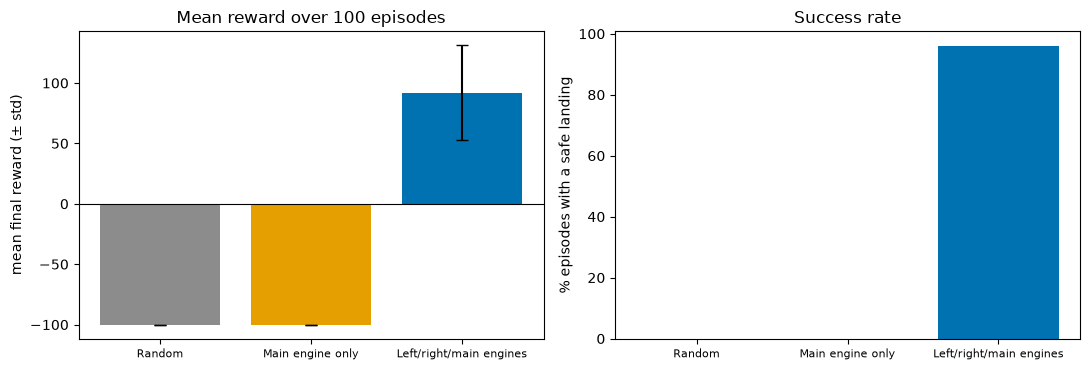

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
colors = ["#8c8c8c", "#e69f00", "#0072b2"]

names = list(results)
axes[0].bar(names, [np.mean(r) for r in results.values()], yerr=[np.std(r) for r in results.values()],
            color=colors, capsize=4)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_ylabel("mean final reward (± std)"); axes[0].set_title("Mean reward over 100 episodes")
axes[0].tick_params(axis="x", labelsize=8)

for name, c in zip(names, colors):
    r = np.array(results[name])
    axes[1].bar(name, np.mean(r == 100) * 100, color=c)
axes[1].set_ylabel("% episodes with a safe landing"); axes[1].set_title("Success rate")
axes[1].tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

### Nhận xét và giải thích

**Kết quả (100 episode, `seed=42`):**

| Tác tử | Reward trung bình | Độ lệch chuẩn | Hạ cánh an toàn (+100) |
|---|---|---|---|
| Ngẫu nhiên | −100,0 | 0,0 | 0/100 |
| Chỉ động cơ chính | −100,0 | 0,0 | 0/100 |
| Trái/phải/chính (cải tiến) | **92,0** | 39,2 | **96/100** |

* **Hai baseline luôn thất bại** (100/100 va chạm): tác tử ngẫu nhiên vừa xoay vừa rơi, còn tác tử chỉ dùng động cơ chính chỉ giảm tốc độ rơi nhưng không kiểm soát được góc nghiêng và vị trí ngang nên trôi lệch ra khỏi bãi đáp hoặc lật.
* **Tác tử cải tiến** hạ cánh an toàn 96% số episode. Reward mỗi episode chỉ có hai giá trị (+100 hoặc −100) nên độ lệch chuẩn 39,2 chính là do 4 lần thất bại: mức ổn định *tốt nhưng không hoàn hảo*: một số điều kiện ban đầu (vận tốc ngang lớn, lực đẩy ban đầu ngẫu nhiên) vẫn khiến nó va chạm.

**Vì sao tác tử phản xạ dựa trên luật cục bộ khó đạt hiệu năng cao trong môi trường liên tục?**

1. **Không có nhìn xa (không lập kế hoạch):** tác tử chỉ phản ứng với quan sát hiện tại. Nhưng động cơ tác động vào *gia tốc*, vận tốc và vị trí thay đổi sau đó (có độ trễ), nên một luật đúng ở thời điểm hiện tại có thể dẫn tới vượt quá mục tiêu (overshoot) hay dao động khi lập kế hoạch nhiều bước mới tránh được. Hạ cánh an toàn là bài toán điều khiển tối ưu nhiều bước, không phải phản xạ tức thời.
2. **Không gian trạng thái liên tục:** vô số tổ hợp $(x, y, v_x, v_y, \theta, \omega)$; các ngưỡng cố định (0,05; 0,4; 0,55; ...) chỉ phân chia không gian này thành một số vùng thô và được điều chỉnh bằng tay quanh các tình huống điển hình. Các trạng thái hiếm (bay rất nhanh ngang, nghiêng lớn sát mặt đất) nằm ngoài vùng được điều chỉnh nên xử lý sai.
3. **Hành động rời rạc (bật/tắt):** động cơ chỉ có bật hoặc tắt hết công suất nên luật ngưỡng tạo ra điều khiển bật-tắt gây rung (chattering) quanh ngưỡng; không có điều chỉnh mượt mà.
4. **Không có bộ nhớ hay mô hình động lực:** tác tử không thể suy ra thứ mà quan sát không cho (ví dụ đang xoay ngày càng nhanh, hoặc đã dao động nhiều lần) và không thể học từ thất bại; khác với tác tử có mô hình (dự đoán quỹ đạo) hoặc học tăng cường (tối ưu hoá reward kỳ vọng).
5. **Mục tiêu phức tạp:** các luật chỉ tối ưu hoá gián tiếp thông qua các đại lượng thay thế (góc, độ cao mong muốn) chứ không tối ưu trực tiếp reward (an toàn, nhiên liệu, thời gian), nên khó cân bằng các mục tiêu trái ngược nhau.

Do đó, để tăng độ ổn định lên gần 100% và tối ưu thêm nhiên liệu/thời gian, cần chuyển sang tác tử có mô hình/lập kế hoạch (ví dụ MPC) hoặc học tăng cường.